# Restaurant Review Sentiment Analysis

**NLP learning project | UCI Yelp reviews | Binary classification**

This is a **reconstruction inspired by the Natural Language Processing section of Udemy's *Machine Learning A-Z*** (Kirill Eremenko / Hadelin de Ponteves), **not an independent research project**. It uses the independently licensed UCI Yelp sentiment subset.

### Question
Can traditional TF-IDF text features and supervised classifiers distinguish clearly positive from clearly negative restaurant-review sentences?

### Workflow
Explore and validate data → deduplicate exact reviews → stratified train/test split → compare Naive Bayes and Logistic Regression by training-only cross-validation → evaluate the selected classifier on held-out data → inspect mistakes → predict sample reviews.

**Dataset credit:** Kotzias, D. (2015), *Sentiment Labelled Sentences*, UCI ML Repository, DOI: [10.24432/C57604](https://doi.org/10.24432/C57604), **CC BY 4.0**. Based on Kotzias, Denil, de Freitas, & Smyth (2015), *From Group to Individual Labels Using Deep Features* (KDD).

In [1]:
import io
import re
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

SEED = 42
UCI_ZIP = "https://archive.ics.uci.edu/static/public/331/sentiment%2Blabelled%2Bsentences.zip"
FALLBACK_FILE = "https://huggingface.co/datasets/IsaacDev/sentiment-labelled-sentences/resolve/main/yelp_labelled.txt"
DATA_PATH = Path("data/yelp_labelled.txt")


## 2. Obtain and validate the Yelp data

The public dataset contains **1,000 restaurant-review sentences (500 per class) before deduplication**. Labels: **0 = negative**, **1 = positive**.


In [3]:

# Downloading the restaurant review dataset

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(exist_ok=True)

    with urllib.request.urlopen(UCI_ZIP) as response:
        data = response.read()

    with zipfile.ZipFile(io.BytesIO(data)) as zip_file:
        for filename in zip_file.namelist():
            if filename.endswith("yelp_labelled.txt"):
                DATA_PATH.write_bytes(zip_file.read(filename))
                break

# Load the dataset
df = pd.read_csv(
    DATA_PATH,
    sep="\t",
    header=None,
    names=["review", "label"],
    quoting=3
)

# Remove empty and duplicate reviews
df = df.dropna()
df = df.drop_duplicates(subset="review")
df = df.reset_index(drop=True)

# Display basic information
print("Total reviews:", len(df))
print("\nSentiment counts:")
print(df["label"].value_counts())

print("\nFirst five reviews:")
display(df.head())


Total reviews: 996

Sentiment counts:
label
1    499
0    497
Name: count, dtype: int64

First five reviews:


,review,label
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


## 3. Inspect dataset balance and length


       count   mean   std  min  25%   50%   75%   max
label                                                
0      497.0  11.54  6.61  2.0  6.0  10.0  16.0  32.0
1      499.0  10.30  5.83  1.0  6.0   9.0  13.5  32.0


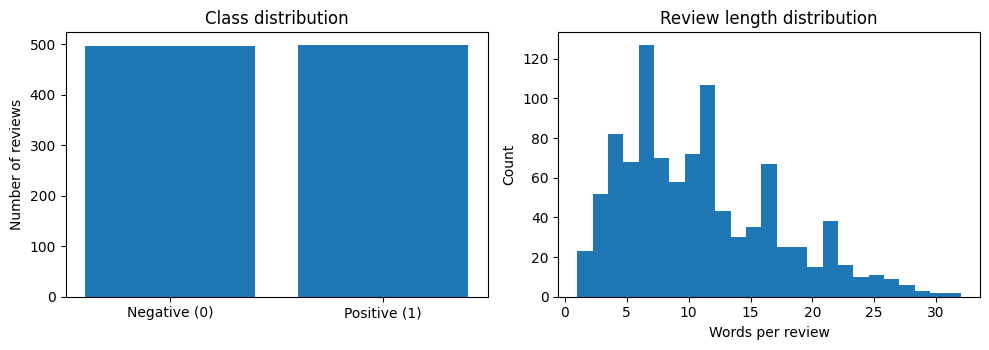

In [4]:
df["review_length_words"] = df["review"].str.split().str.len()
print(df.groupby("label")["review_length_words"].describe().round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
counts = df["label"].value_counts().reindex([0, 1])
axes[0].bar(["Negative (0)", "Positive (1)"], counts.values)
axes[0].set_title("Class distribution")
axes[0].set_ylabel("Number of reviews")
axes[1].hist(df["review_length_words"], bins=25)
axes[1].set_title("Review length distribution")
axes[1].set_xlabel("Words per review")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

## 4. Split **before** learning text features

Note to remember : Use a **stratified 80/20 split**. Minimal text cleanup preserves words such as *not* and *never*. The TF-IDF vectorizer sits **inside** each model pipeline, so its vocabulary and IDF statistics are never fitted on the held-out test split or a cross-validation validation fold.

In [5]:

# Clean the restaurant reviews
X = df["review"].astype(str)

# Remove URLs and extra spaces
X = X.str.replace(r"https?://\S+", " ", regex=True)
X = X.str.replace(r"\s+", " ", regex=True)
X = X.str.strip()

# Sentiment labels (0 = Negative, 1 = Positive)
y = df["label"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nExample cleaned review:")
print(X.iloc[0])


Training reviews: 796
Testing reviews: 200

Example cleaned review:
Wow... Loved this place.


## 5. Compare models using training-only cross-validation

My Notes: I compare Multinomial Naive Bayes and Logistic Regression with **5-fold stratified CV**, scored by **macro-F1**. This choice gives equal weight to negative and positive classes. Then  select the model by CV results, **not by the held-out test score**.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
candidates = {
    "Multinomial Naive Bayes": build_model(MultinomialNB(alpha=1.0)),
    "Logistic Regression": build_model(LogisticRegression(max_iter=1000, random_state=SEED)),
}
score_rows = []
for name, estimator in candidates.items():
    scores = cross_val_score(estimator, X_train, y_train, cv=cv, scoring="f1_macro")
    score_rows.append({
        "model": name,
        "mean_CV_macro_F1": float(scores.mean()),
        "std_CV_macro_F1": float(scores.std()),
    })
comparison = pd.DataFrame(score_rows).sort_values("mean_CV_macro_F1", ascending=False).reset_index(drop=True)
display(comparison.round(3))
selected_model_name = str(comparison.loc[0, "model"])
print("Model selected using training-only CV:", selected_model_name)

,model,mean_CV_macro_F1,std_CV_macro_F1
0,Multinomial Naive Bayes,0.797,0.013
1,Logistic Regression,0.793,0.029


Model selected using training-only CV: Multinomial Naive Bayes


## 6. Held-out test evaluation

Majority-class baseline accuracy: 0.500
Selected model held-out accuracy: 0.820
Selected model held-out macro-F1: 0.820

Classification report (held-out test):
              precision    recall  f1-score   support

    Negative      0.848     0.780     0.812       100
    Positive      0.796     0.860     0.827       100

    accuracy                          0.820       200
   macro avg      0.822     0.820     0.820       200
weighted avg      0.822     0.820     0.820       200



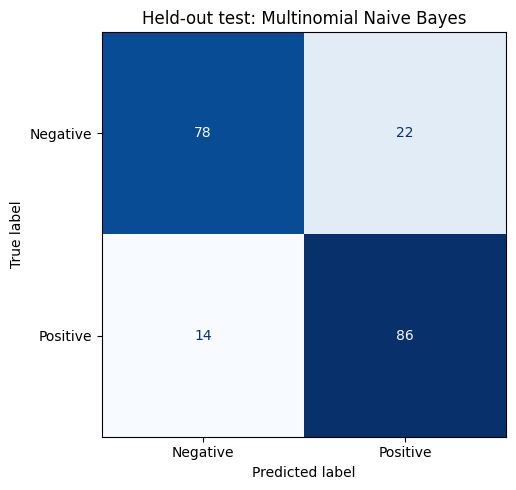

In [15]:
selected_pipeline = candidates[selected_model_name]
selected_pipeline.fit(X_train, y_train)
y_pred = selected_pipeline.predict(X_test)
y_prob_positive = selected_pipeline.predict_proba(X_test)[:, 1]

majority_baseline = build_model(DummyClassifier(strategy="most_frequent"))
majority_baseline.fit(X_train, y_train)
y_baseline = majority_baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, y_baseline)
heldout_accuracy = accuracy_score(y_test, y_pred)
heldout_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Majority-class baseline accuracy: {baseline_accuracy:.3f}")
print(f"Selected model held-out accuracy: {heldout_accuracy:.3f}")
print(f"Selected model held-out macro-F1: {heldout_f1:.3f}")
print("\nClassification report (held-out test):")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=3, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title(f"Held-out test: {selected_model_name}")
plt.tight_layout()
plt.show()

## 7. Error analysis — what does the model miss?

Inspect mistakes, especially mixed sentiment, uncommon expressions, implicit sentiment, negation, and unusual wording. These examples tell us more than accuracy alone. Predicted probabilities are **not calibrated**.

In [16]:
review_errors = pd.DataFrame({
    "review": X_test.to_numpy(),
    "true_label": y_test.to_numpy(),
    "predicted_label": y_pred,
    "estimated_P_positive": y_prob_positive,
})
wrong = review_errors[review_errors["true_label"] != review_errors["predicted_label"]]
print(f"Wrong predictions: {len(wrong)} of {len(X_test)} test reviews")
if wrong.empty:
    print("No mistakes observed in this split.")
else:
    display(wrong.head(10))

Wrong predictions: 36 of 200 test reviews


,review,true_label,predicted_label,estimated_P_positive
3,"Host staff were, for lack of a better word, BI...",0,1,0.557624
11,I was seated immediately.,1,0,0.461888
14,The place was not clean and the food oh so stale!,0,1,0.600016
18,I found this place by accident and I could not...,1,0,0.367060
26,Nicest Chinese restaurant I've been in a while.,1,0,0.463871
36,"The meat was pretty dry, I had the sliced bris...",0,1,0.522966
55,I was so insulted.,0,1,0.518391
56,Never had anything to complain about here.,1,0,0.347240
59,What I really like there is the crepe station.,1,0,0.397632
63,The selection of food was not the best.,0,1,0.572325


## 8. Interpreting influential terms

The terms below have comparatively strong associations with the positive or negative class in the fitted linear/multinomial classifier. They are **not causal explanations**, and individual errors can occur even when a phrase seems easy to interpret.

In [17]:
vocabulary = selected_pipeline.named_steps["tfidf"].get_feature_names_out()
fitted = selected_pipeline.named_steps["classifier"]
if hasattr(fitted, "coef_"):
    importance = fitted.coef_[0]
else:
    importance = fitted.feature_log_prob_[1] - fitted.feature_log_prob_[0]

positive_terms = vocabulary[np.argsort(importance)[-10:][::-1]]
negative_terms = vocabulary[np.argsort(importance)[:10]]
print("Positive-associated terms:", ", ".join(positive_terms))
print("Negative-associated terms:", ", ".join(negative_terms))

Positive-associated terms: great, delicious, amazing, fantastic, friendly, awesome, very good, loved, was good, excellent
Negative-associated terms: not, terrible, bad, don, not good, minutes, worst, slow, would not, probably


## 9. Predict unseen example sentences

These are illustrative synthetic sentences and **not** proof of performance on new restaurants.

In [18]:
sample_reviews = [
    "The staff were friendly and our meal was delicious.",
    "The food was cold and the server was rude.",
    "The food was not good, but the service was friendly.",
]
labels = selected_pipeline.predict(sample_reviews)
probabilities = selected_pipeline.predict_proba(sample_reviews)[:, 1]
for sentence, label, prob in zip(sample_reviews, labels, probabilities):
    print(f"Review: {sentence}")
    print(f"Prediction: {'Positive' if label else 'Negative'} | estimated P(positive): {prob:.3f}\n")

Review: The staff were friendly and our meal was delicious.
Prediction: Positive | estimated P(positive): 0.878

Review: The food was cold and the server was rude.
Prediction: Negative | estimated P(positive): 0.450

Review: The food was not good, but the service was friendly.
Prediction: Negative | estimated P(positive): 0.442



## 10. Results summary and reflection

Copy the **actual** values printed below into `README.md` after you run this notebook. Then add a few sentences *in your own words* about one real misclassification observed above. This is a coursework-inspired exercise, not novel NLP research.

In [19]:
print(f"Unique review sentences after deduplication: {len(df)}")
print(f"Train/test size: {len(X_train)}/{len(X_test)}")
print(f"Selected by training-only CV: {selected_model_name}")
print(f"CV macro-F1 (mean ± SD): {comparison.iloc[0]['mean_CV_macro_F1']:.3f} ± {comparison.iloc[0]['std_CV_macro_F1']:.3f}")
print(f"Majority baseline accuracy: {baseline_accuracy:.3f}")
print(f"Held-out test accuracy: {heldout_accuracy:.3f}")
print(f"Held-out test macro-F1: {heldout_f1:.3f}")
print("\nReflect on an error above before publishing your application portfolio.")

Unique review sentences after deduplication: 996
Train/test size: 796/200
Selected by training-only CV: Multinomial Naive Bayes
CV macro-F1 (mean ± SD): 0.797 ± 0.013
Majority baseline accuracy: 0.500
Held-out test accuracy: 0.820
Held-out test macro-F1: 0.820

Reflect on an error above before publishing your application portfolio.


### Limitations and next steps

- This small, balanced, English-only dataset has intentionally clear sentiment; results should not be generalized to all Yelp reviews.
- Reviews containing sarcasm, mixed opinions, domain-specific terms, or neutral sentiment may be misclassified.
- We can remove exact duplicate text, not semantic duplicates or near-duplicates.
- Hyperparameters are not tuned here; different splits or a larger corpus could change comparisons.
- A possible next learning step is to evaluate the same pipeline across **different review domains** and compare errors — especially relevant to studying model robustness under distribution shifts.

**Repository documentation:** see `README.md` and `data/README.md.